## Multi-Agent 多智能体

Multi Agent，既多智能体协作系统，专门用来处理复杂的任务流程。

### 1. Multi-Agent 模式
LangChain中提供了四种不同的MultiAgent模式。

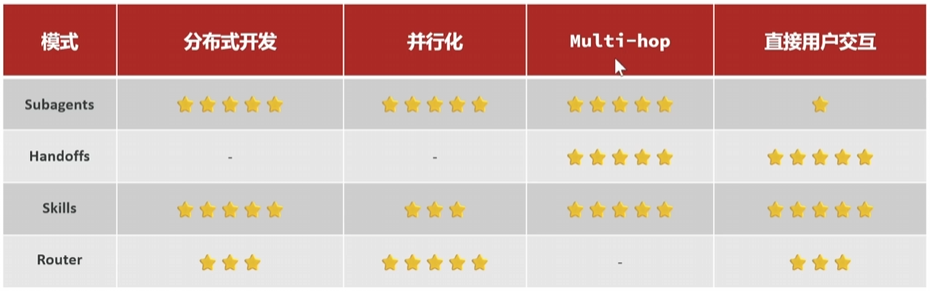


我们从四个方面来对比这几种模式：
- Distributed development：是否支持不同团队独立开发维护
- Parallelization：是否支持并行运行多个subagent
- Multi-hop：是否支持按照特定顺序依次执行多个subagent
- Direct user interaction：是否支持subagent直接与用户对话
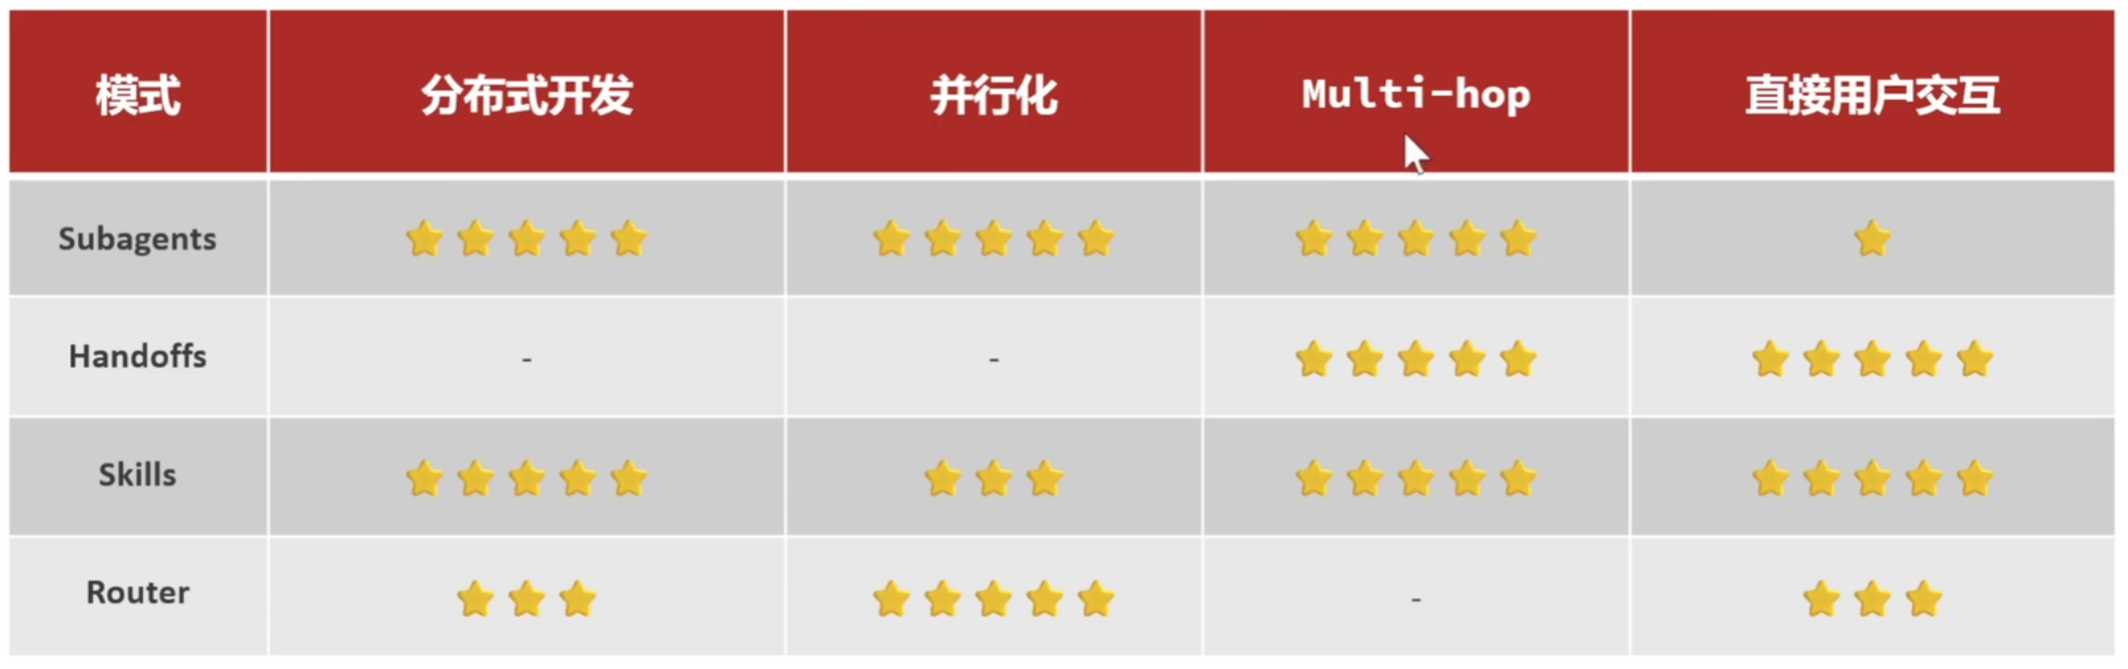

#### 1.1 SubAgents 子智能体模式

一个 `Main Agent` 将多个 `Sub-Agent` 作为 Tool 来协调使用。所有 request 和 response 都由 `Main Agent` 处理，并决定何时以及如何调用每个 `Sub-Agent`


    官网介绍：https://docs.langchain.com/oss/python/langchain/multi-agent/subagents

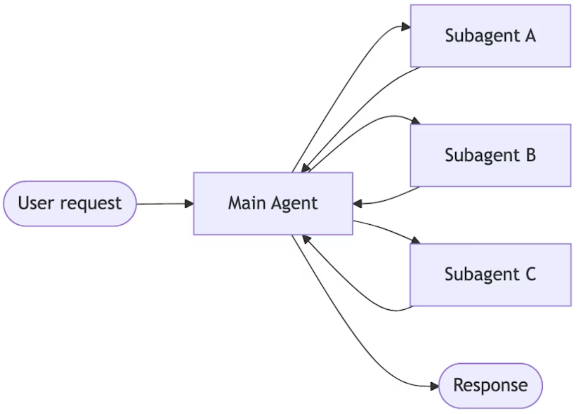

#### 1.2 Handoffs 传递模式
多个 Agent 之间没有主次之分，形成固定工作流


官网介绍：https://docs.langchain.com/oss/python/langchain/multi-agent/handoffs

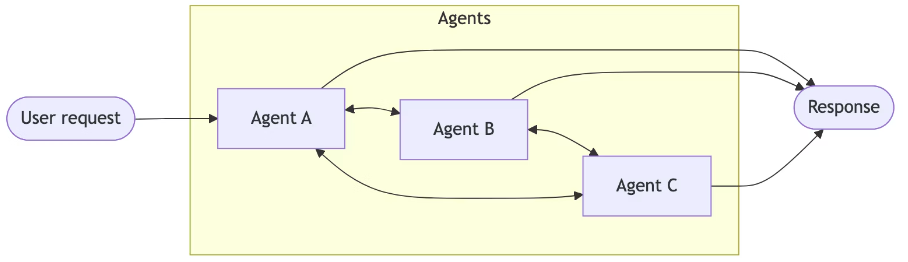

#### 1.3 Skills模式
只有 1 个 Agent，根据任务按需加载 Skill


官网介绍：https://docs.langchain.com/oss/python/langchain/multi-agent/skills


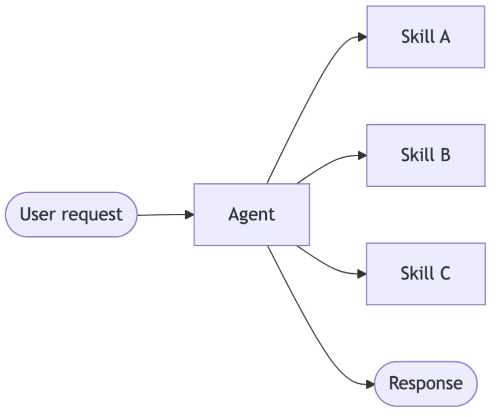

#### 1.4 Router 路由模式

1个负责路由的Agent对用户请求进行分类，将请求导向给一个或多个专门的Agent。最后再由一个Agent负责总结结果

官网介绍：https://docs.langchain.com/oss/python/langchain/multi-agent/router

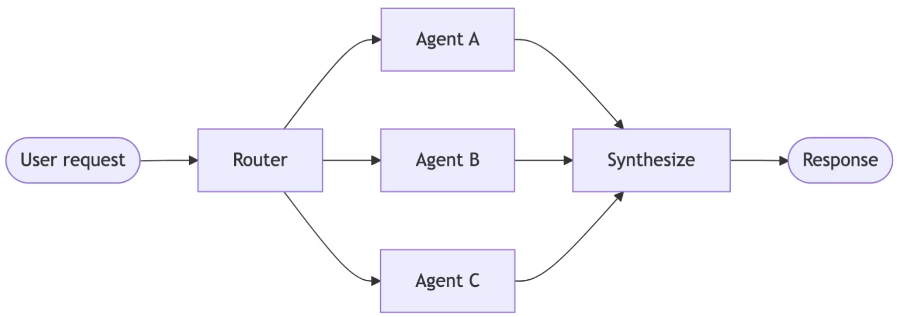

### 2. 婚礼 Agent 案例

现在，我们计划开发一个婚礼策划智能体，它包含以下三个核心功能：
- 旅行规划：负责为你和宾客前往婚礼目的地寻找合适的机票，制定旅行计划
- 场地规划：负责根据宾客人数在目的地寻找合适的婚礼场地
- 音乐规划：负责根据用户需求筛选合适的婚礼歌单，并计算出预算

#### 2.1 需求分析

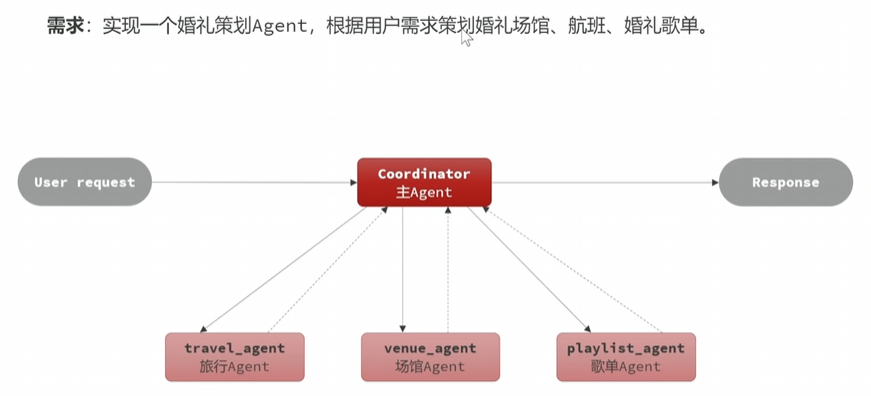

理论上说，我们只要准备好以上每一步所需的工具，写好包含完整流程的系统提示词，用一个Agent就能实现这个功能。

但是，考虑到以下几个原因：
- 要使用的工具实在是太多，航班、场地、音乐等要查询的信息非常多，这会导致单Agent的上下文非常大，有可能超出模型上下文限制。把任务拆解可以减少上下文需求，因此适合分布式开发。
- 旅行、场地、音乐的三个任务没有关联，为了提高效率，可以并行执行

综上，建议采用多Agent开发，模式可以选择Subagents模式。我们可以开发三个Subagent：
- travel agent：负责为你前往婚礼目的地寻找往返机票
- venue agent：负责根据宾客人数在网上搜索合适的婚礼场地
- playlist agent：负责在音乐数据库筛选符合用户需求的歌单，并计算出预算

最后，我们还会定义一个主Agent，负责协调（Coordinator）工作，以及生成最终的婚礼计划方案。